In [50]:
import tensorflow as tf
import numpy as np
import pandas as pd
from pylab import rcParams
import matplotlib.pylab as plt
import warnings
from mlxtend.plotting import plot_decision_regions
from matplotlib.colors import ListedColormap
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles
import seaborn as sns

### **We create our won classification dataset**

In [51]:
X, y = make_circles(
    n_samples = 100,
    noise = 0.1,
    random_state = 1
)

<Axes: >

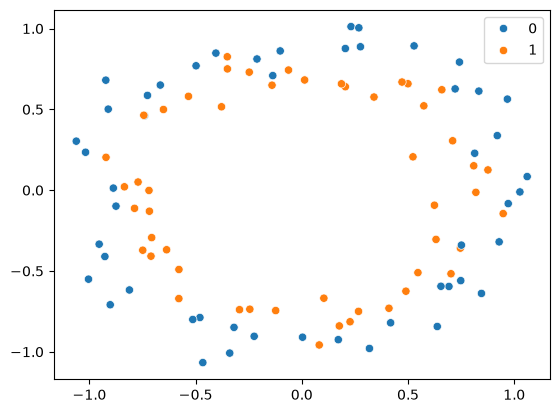

In [52]:
sns.scatterplot(
    x = X[ : , 0],
    y = X[ : , 1],
    hue = y
)

In [53]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 2)

In [54]:
model = Sequential()

model.add(Dense(256, input_dim = 2, activation = 'relu'))
model.add(Dense(1, activation = 'sigmoid'))

d:\Rat_Race\AI-ML\env\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [55]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 256)            │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,025 (4.00 KB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 0 (0.00 B)

In [56]:
model.compile(
    loss = 'binary_crossentropy',
    optimizer = 'adam',
    metrics = ['accuracy']
)

In [57]:
history = model.fit(
    X_train,
    y_train,
    validation_data = (X_test, y_test),
    epochs = 3500,
    verbose = 0
)

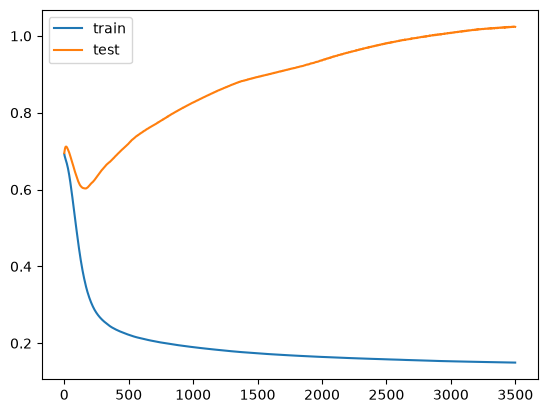

In [58]:
plt.plot(
    history.history['loss'], 
    label = 'train'
)
plt.plot(
    history.history['val_loss'], 
    label = 'test'
)
plt.legend()
plt.show()

In [59]:
# plot_decision_regions(
#     X_test,
#     y_test.ravel().astype(int),
#     clf=model,
#     legend=2
# )
# plt.show()

### **Early Stopping**

In [60]:
model = Sequential()

model.add(Dense(256, input_dim = 2, activation = 'relu'))
model.add(Dense(1, activation = 'sigmoid'))

In [61]:
model.compile(
    loss = 'binary_crossentropy',
    optimizer = 'adam',
    metrics = ['accuracy']
)

In [62]:
callback = EarlyStopping(
    monitor = 'val_loss',
    min_delta = 0.00001,
    patience = 20,
    verbose = 1,
    mode = 'auto',
    baseline = None,
    restore_best_weights = False
)

In [63]:
history = model.fit(
    X_train,
    y_train,
    validation_data = (X_test, y_test),
    epochs = 3500, 
    callbacks = callback
)

Epoch 1/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.4875 - loss: 0.6916 - val_accuracy: 0.5000 - val_loss: 0.6999
Epoch 2/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5125 - loss: 0.6893 - val_accuracy: 0.4500 - val_loss: 0.7019
Epoch 3/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5250 - loss: 0.6877 - val_accuracy: 0.4000 - val_loss: 0.7038
Epoch 4/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5375 - loss: 0.6863 - val_accuracy: 0.4000 - val_loss: 0.7055
Epoch 5/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5500 - loss: 0.6850 - val_accuracy: 0.4000 - val_loss: 0.7071
Epoch 6/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5625 - loss: 0.6838 - val_accuracy: 0.4000 - val_loss: 0.7085
Epoch 7/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5500 - loss: 0.6827 - val_accuracy: 0.4000 - val_loss: 0.7097
Epoch 8/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5500 - loss: 0.6816 - val_accuracy: 0.4000 - 

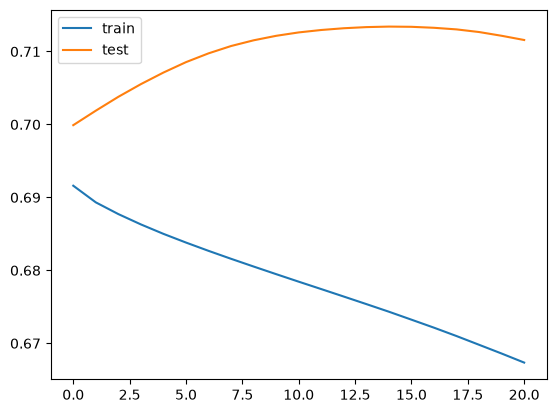

In [64]:
plt.plot(history.history['loss'], label = 'train')
plt.plot(history.history['val_loss'], label = 'test')
plt.legend()
plt.show()